In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("AI_Usage_and_Impact_on_Students_and_Professionals.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    object 
 1   Age                          277 non-null    object 
 2   Gender                       290 non-null    object 
 3   Country                      290 non-null    object 
 4   User_Type                    300 non-null    object 
 5   Education_Level              287 non-null    object 
 6   Profession                   285 non-null    object 
 7   Monthly_Income               290 non-null    object 
 8   AI_Tool                      289 non-null    object 
 9   AI_Purpose                   287 non-null    object 
 10  AI_Usage_Hours_Per_Day       293 non-null    object 
 11  Tasks_Performed              282 non-null    object 
 12  Monthly_AI_Cost              288 non-null    object 
 13  Productivity_Score  

In [59]:
df = df.drop_duplicates()

In [60]:
df.shape

(288, 19)

In [4]:
df['Age'] = pd.to_numeric(df['Age'],errors='coerce')

In [5]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [6]:
df['Age'].isnull().sum()

0

In [7]:
df['Gender'] = df['Gender'].str.strip().str.title()
df['Gender'] = df['Gender'].replace({
    "M" : "Male",
    "F" : "Female"
})

In [8]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [9]:
df['Gender'].value_counts(dropna=False)

Gender
Male          161
Female        123
Other          15
Non-Binary      1
Name: count, dtype: int64

In [10]:
df['Country'] = df['Country'].str.strip().str.title()
df['Country'] = df['Country'].replace({
    'U.K.': 'United Kingdom',
    'United States Of America': 'United States'})

In [11]:
df['Country'] = df['Country'].fillna("Unknown")

In [12]:
df['Country'].value_counts(dropna=False)

Country
India             45
United States     35
Canada            34
Pakistan          29
United Kingdom    27
Brazil            27
Philippines       25
Australia         21
Nigeria           17
Germany           13
France            11
Unknown           10
Kenya              6
Name: count, dtype: int64

In [13]:
df['Education_Level'] = df['Education_Level'].str.strip().str.title()
df['Education_Level'] = df['Education_Level'].replace({
    "Bachelor'S" : "Bachelor's",
    "Bachelors" : "Bachelor's",
    "Bachelor'S Degree" : "Bachelor's",
    "Undergrad" : "Undergraduate", 
    "Master'S" : "Master's",
    "Masters" : "Master's", 
    "Master'S Degree" : "Master's", 
    "Hs" :"High School", 
    "Ph.D." : "Ph.D", 
    "Phd" : "Ph.D",
    'Ba/Bsc': "Bachelor's",
    'Ma/Msc': "Master's"

})
df['Education_Level'].value_counts()
df['Education_Level'].isnull().sum()
df['Education_Level'] = df['Education_Level'].fillna("Unknown")

In [14]:
df['Education_Level'].value_counts(dropna=False)

Education_Level
Bachelor's       76
Undergraduate    64
Master's         57
High School      48
Diploma          25
Ph.D             17
Unknown          13
Name: count, dtype: int64

In [15]:
df['Profession'] = df['Profession'].str.strip().str.title()
df['Profession'] = df['Profession'].fillna("Unknown")
df['Profession'].isnull().sum()

0

In [16]:
df['Profession'].value_counts(dropna=False)

Profession
English Literature Student                                     24
Computer Science Student                                       18
Unknown                                                        15
Mechanical Engineering Student                                 11
Biology Student                                                11
                                                               ..
Développeur Full Stack                                          1
Desenvolvedora De Sistemas Júnior                               1
Customer Support Specialist / Ai Support Operations Manager     1
Social Media Content Creator                                    1
Desenvolvedor De Sistemas (Systems Developer)                   1
Name: count, Length: 127, dtype: int64

In [17]:
df['Monthly_Income'] = pd.to_numeric(df['Monthly_Income'],errors="coerce") 

In [18]:
df['Monthly_Income'] = df['Monthly_Income'].fillna(df['Monthly_Income'].mean())

In [19]:
df['AI_Tool'] = df['AI_Tool'].str.strip().str.title()
df['AI_Tool'] = df['AI_Tool'].replace({
    "Chat Gpt" : "Chatgpt", 
    "Copilot" : "Microsoft Copilot",
    "Gemini" : "Google Gemini"
})

In [20]:
df['AI_Tool'] = df['AI_Tool'].fillna(df['AI_Tool'].mode()[0])

In [21]:
df['AI_Tool'].value_counts()

AI_Tool
Chatgpt              133
Google Gemini         41
Microsoft Copilot     36
Claude                31
Perplexity Ai         25
Grammarly             14
Meta Ai               10
Deepseek              10
Name: count, dtype: int64

In [22]:
df['AI_Purpose'].isnull().sum()
df['AI_Purpose'] = df['AI_Purpose'].fillna(df['AI_Purpose'].mode()[0])

In [23]:
df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30.0,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,Chatgpt,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30.0,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,Chatgpt,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17.0,Male,Canada,Student,Unknown,Computer Science Student,402.0,Chatgpt,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35.0,Female,Brazil,Professional,Bachelor's,Desenvolvedora De Software / Software Developer,1367.0,Meta Ai,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19.0,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity Ai,Coding,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


In [24]:
df['AI_Usage_Hours_Per_Day'] = pd.to_numeric(
    df['AI_Usage_Hours_Per_Day'].astype(str).str.replace('hrs', '', regex=False).str.strip(),errors="coerce")
df['AI_Usage_Hours_Per_Day'] = df['AI_Usage_Hours_Per_Day'].fillna(df['AI_Usage_Hours_Per_Day'].median())

In [25]:
df['Tasks_Performed'] = df['Tasks_Performed'].fillna("Unknown")

In [26]:
df['Monthly_AI_Cost'] = pd.to_numeric(df['Monthly_AI_Cost'],errors='coerce')

In [27]:
df['Monthly_AI_Cost'] = df['Monthly_AI_Cost'].fillna(df['Monthly_AI_Cost'].median())

In [28]:
df['Productivity_Score'] = df['Productivity_Score'].fillna(df['Productivity_Score'].median())

In [29]:
df['Accuracy_Rating'] = df['Accuracy_Rating'].fillna(df['Accuracy_Rating'].median())

In [30]:
df['Satisfaction_Score'] = df['Satisfaction_Score'].fillna(df['Satisfaction_Score'].median())

In [31]:
df['Time_Saved_Hours_Per_Week'] = pd.to_numeric(
    df['Time_Saved_Hours_Per_Week'].astype(str).str.replace('hrs', '', regex=False).str.strip(),
    errors='coerce'
)

In [32]:
df['Time_Saved_Hours_Per_Week'] = df['Time_Saved_Hours_Per_Week'].fillna(
    df['Time_Saved_Hours_Per_Week'].median()
)

In [33]:
df['Work_or_Study_Hours_Per_Day'] = pd.to_numeric(
    df['Work_or_Study_Hours_Per_Day'].astype(str).str.replace('hrs', '', regex=False).str.strip(),
    errors='coerce'
)

In [34]:
df['Work_or_Study_Hours_Per_Day'] = df['Work_or_Study_Hours_Per_Day'].fillna(
    df['Work_or_Study_Hours_Per_Day'].median()
)

In [35]:
df['Would_Recommend'] = df['Would_Recommend'].fillna(df['Would_Recommend'].mode()[0])

In [36]:
df[df["AI_Usage_Hours_Per_Day"] > 12][
    ["User_ID", "AI_Usage_Hours_Per_Day", "Work_or_Study_Hours_Per_Day"]].sort_values( by="AI_Usage_Hours_Per_Day", ascending=False)

,User_ID,AI_Usage_Hours_Per_Day,Work_or_Study_Hours_Per_Day
19,U0046,23.0,9.5


In [63]:
df.isnull().sum()

User_ID                        0
Age                            0
Gender                         0
Country                        0
User_Type                      0
Education_Level                0
Profession                     0
Monthly_Income                 0
AI_Tool                        0
AI_Purpose                     0
AI_Usage_Hours_Per_Day         0
Tasks_Performed                0
Monthly_AI_Cost                0
Productivity_Score             0
Accuracy_Rating                0
Satisfaction_Score             0
Time_Saved_Hours_Per_Week      0
Work_or_Study_Hours_Per_Day    0
Would_Recommend                0
dtype: int64

In [64]:
columns_to_check = [
    "Age",
    "AI_Usage_Hours_Per_Day",
    "Productivity_Score",
    "Accuracy_Rating",
    "Satisfaction_Score",
    "Time_Saved_Hours_Per_Week",
    "Work_or_Study_Hours_Per_Day",
    "Monthly_AI_Cost"
]
df[columns_to_check].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,288.0,30.230513,11.801178,16.0,22.000,29.0,34.000,97.0
AI_Usage_Hours_Per_Day,288.0,2.921181,2.436940,0.5,1.375,2.1,3.925,23.0
Productivity_Score,288.0,5.223611,1.777521,1.6,4.000,5.0,6.200,10.0
Accuracy_Rating,288.0,3.444444,0.845383,2.0,3.000,4.0,4.000,5.0
Satisfaction_Score,288.0,6.128472,1.507526,3.0,5.000,6.0,7.000,10.0
Time_Saved_Hours_Per_Week,288.0,5.781944,4.045062,0.0,2.875,5.0,7.500,19.4
Work_or_Study_Hours_Per_Day,288.0,7.251736,1.963996,2.1,6.100,7.2,8.400,20.0
Monthly_AI_Cost,288.0,8.906250,13.445006,0.0,0.000,0.0,20.000,100.0


In [65]:
df[df["User_ID"] == "U0046"].T

,19
User_ID,U0046
Age,61.0
Gender,Female
Country,Nigeria
User_Type,Professional
Education_Level,Diploma
Profession,Research Technician
Monthly_Income,585.0
AI_Tool,Google Gemini
AI_Purpose,Research


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 288 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      288 non-null    object 
 1   Age                          288 non-null    float64
 2   Gender                       288 non-null    object 
 3   Country                      288 non-null    object 
 4   User_Type                    288 non-null    object 
 5   Education_Level              288 non-null    object 
 6   Profession                   288 non-null    object 
 7   Monthly_Income               288 non-null    float64
 8   AI_Tool                      288 non-null    object 
 9   AI_Purpose                   288 non-null    object 
 10  AI_Usage_Hours_Per_Day       288 non-null    float64
 11  Tasks_Performed              288 non-null    object 
 12  Monthly_AI_Cost              288 non-null    float64
 13  Productivity_Score       

In [67]:
df.head(20)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30.00000,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,Chatgpt,Office Work,2.0,Data analysis using AI-powered analytics tools...,0.0,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30.00000,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,Chatgpt,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.4,8.4,Yes
2,U0152,17.00000,Male,Canada,Student,Unknown,Computer Science Student,402.0,Chatgpt,Coding,1.0,Unknown,20.0,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35.00000,Female,Brazil,Professional,Bachelor's,Desenvolvedora De Software / Software Developer,1367.0,Meta Ai,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19.00000,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity Ai,Coding,4.1,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.2,6.2,Yes
5,U0225,19.00000,Male,United States,Student,Undergraduate,Business Analytics Student,774.0,Meta Ai,Data Analysis,1.5,"Statistical analysis on datasets, data visuali...",0.0,5.0,3.0,6.0,2.9,7.4,No
6,U0246,32.00000,Male,France,Professional,Bachelor's,Développeur Full Stack,4466.0,Chatgpt,Coding,1.2,"Automated code review with AI-powered linters,...",20.0,3.0,2.0,5.0,6.6,6.4,Yes
7,U0177,32.00000,Male,Philippines,Professional,High School,Social Media Content Creator,486.0,Chatgpt,Content Creation,2.0,Creating Instagram/TikTok captions with AI wri...,0.0,6.5,2.0,5.0,3.2,6.4,Yes
8,U0207,16.00000,Male,Philippines,Student,Undergraduate,Digital Media Production Student,132.0,Claude,Content Creation,1.6,"Creating YouTube video scripts, Designing soci...",30.0,4.7,4.0,6.0,3.8,3.8,Yes
9,U0167,40.00000,Male,India,Professional,High School,Unknown,1595.0,Chatgpt,Writing,1.7,"Email copywriting, Social media post creation,...",10.0,5.0,2.0,5.0,7.5,9.4,Maybe


In [80]:
df.describe()

,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day
count,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000
mean,30.230513,2367.497653,2.921181,8.906250,5.223611,3.444444,6.128472,5.781944,7.251736
std,11.801178,14786.471920,2.436940,13.445006,1.777521,0.845383,1.507526,4.045062,1.963996
min,16.000000,0.000000,0.500000,0.000000,1.600000,2.000000,3.000000,0.000000,2.100000
25%,22.000000,129.000000,1.375000,0.000000,4.000000,3.000000,5.000000,2.875000,6.100000
50%,29.000000,555.000000,2.100000,0.000000,5.000000,4.000000,6.000000,5.000000,7.200000
75%,34.000000,2328.957746,3.925000,20.000000,6.200000,4.000000,7.000000,7.500000,8.400000
max,97.000000,250000.000000,23.000000,100.000000,10.000000,5.000000,10.000000,19.400000,20.000000


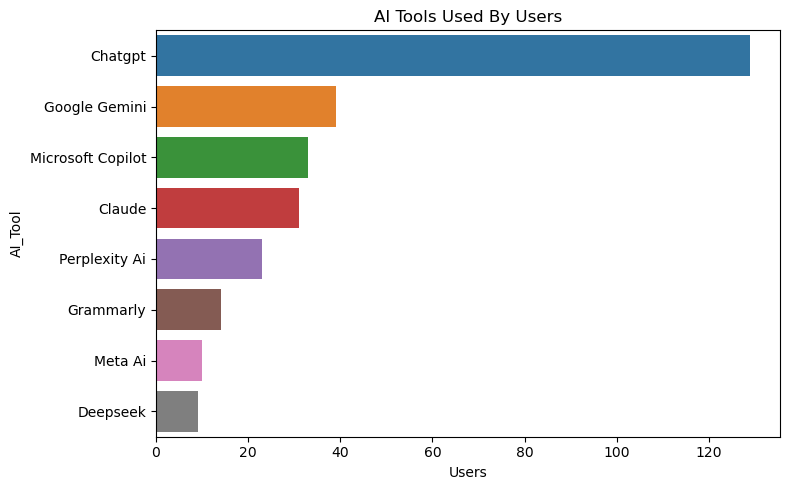

In [68]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df , y = "AI_Tool" ,order=df['AI_Tool'].value_counts().index)
plt.title("AI Tools Used By Users")
plt.xlabel("Users")
plt.tight_layout()

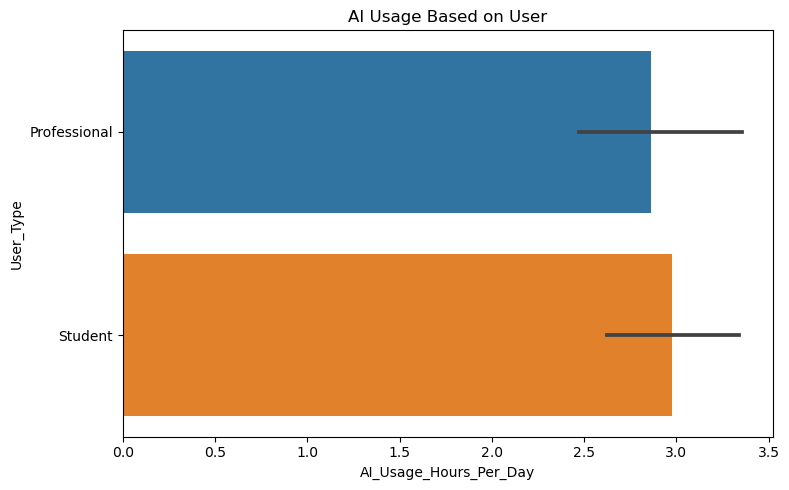

In [69]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df , x = "AI_Usage_Hours_Per_Day" , y = "User_Type")
plt.title("AI Usage Based on User")
plt.tight_layout()

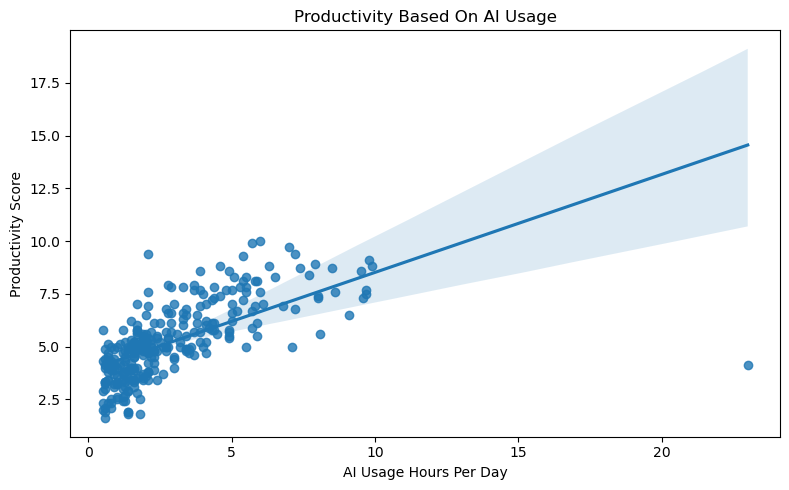

In [70]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df , x = "AI_Usage_Hours_Per_Day" , y = "Productivity_Score")
plt.title("Productivity Based On AI Usage")
plt.xlabel("AI Usage Hours Per Day")
plt.ylabel("Productivity Score")
plt.tight_layout()

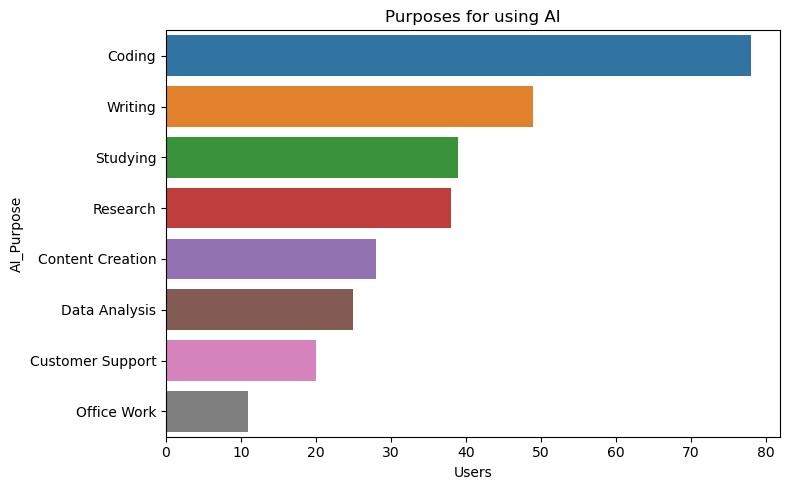

In [71]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df , y = "AI_Purpose" ,order=df["AI_Purpose"].value_counts().index)
plt.title("Purposes for using AI")
plt.xlabel("Users")
plt.tight_layout()

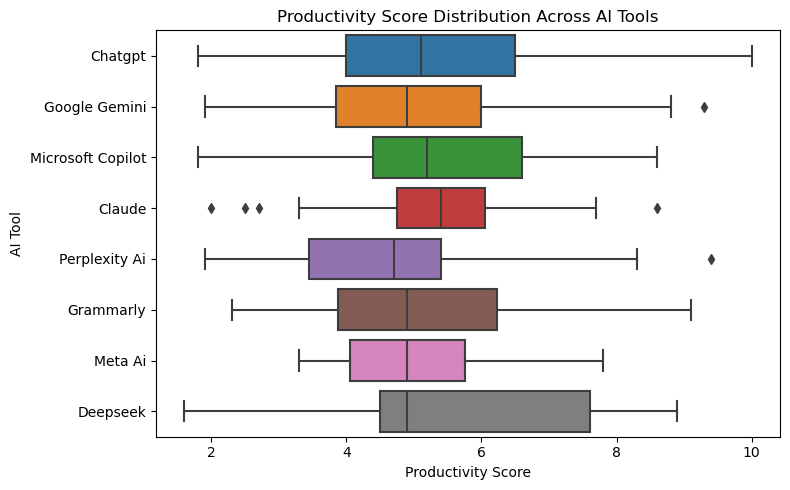

In [72]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Productivity_Score", y="AI_Tool" ,order=df["AI_Tool"].value_counts().index)
plt.title("Productivity Score Distribution Across AI Tools")
plt.xlabel("Productivity Score")
plt.ylabel("AI Tool")
plt.tight_layout()

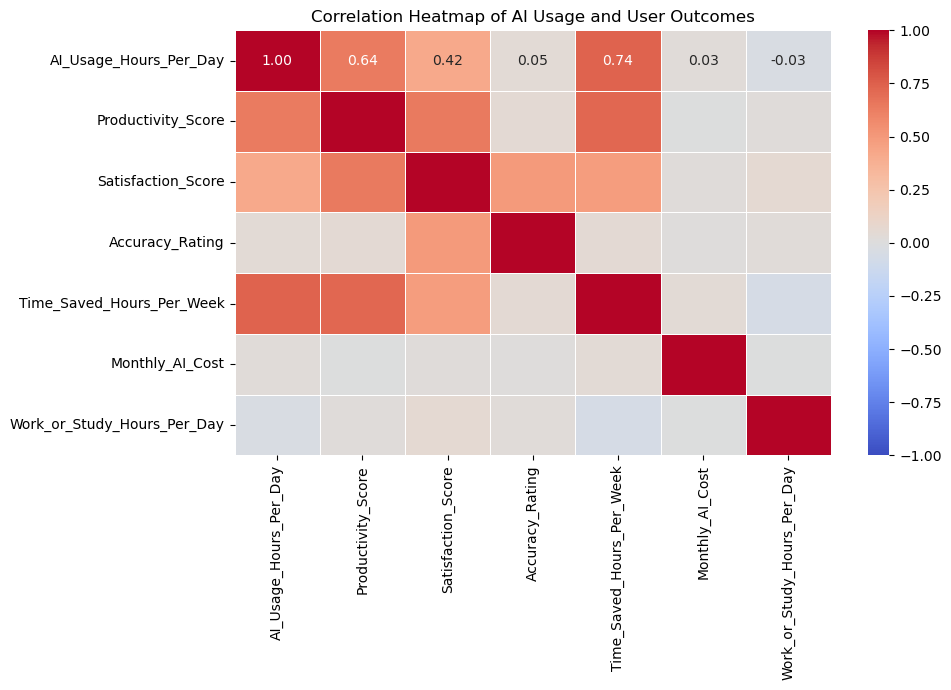

In [73]:
cols = ["AI_Usage_Hours_Per_Day","Productivity_Score","Satisfaction_Score","Accuracy_Rating","Time_Saved_Hours_Per_Week",
        "Monthly_AI_Cost","Work_or_Study_Hours_Per_Day"]

corr_matrix = df[cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix , annot=True, cmap="coolwarm", fmt=".2f" , linewidths=0.5 , vmin=-1 , vmax=1  )
plt.title("Correlation Heatmap of AI Usage and User Outcomes")
plt.tight_layout()

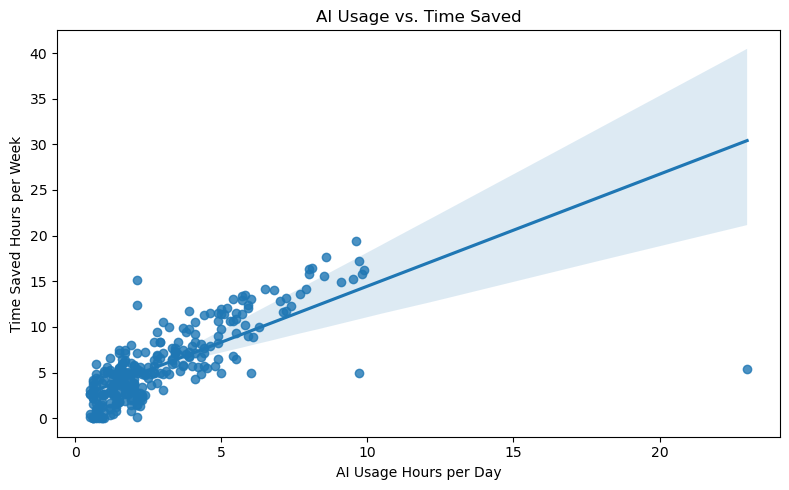

In [74]:
plt.figure(figsize=(8, 5))
sns.regplot( data=df, x="AI_Usage_Hours_Per_Day", y="Time_Saved_Hours_Per_Week")
plt.title("AI Usage vs. Time Saved")
plt.xlabel("AI Usage Hours per Day")
plt.ylabel("Time Saved Hours per Week")
plt.tight_layout()

In [75]:
# 1. Average daily AI usage
print("Average AI Usage per Day:",
      df["AI_Usage_Hours_Per_Day"].mean().round(2))

# 2. Average productivity score
print("Average Productivity Score:",
      df["Productivity_Score"].mean().round(2))

# 3. Average satisfaction score
print("Average Satisfaction Score:",
      df["Satisfaction_Score"].mean().round(2))

# 4. Average time saved per week
print("Average Time Saved per Week:",
      df["Time_Saved_Hours_Per_Week"].mean().round(2))

# 5. Percentage of users who would recommend AI
print("Users Who Would Recommend AI (%):",
      (df["Would_Recommend"].eq("Yes").mean() * 100).round(2))

Average AI Usage per Day: 2.92
Average Productivity Score: 5.22
Average Satisfaction Score: 6.13
Average Time Saved per Week: 5.78
Users Who Would Recommend AI (%): 60.76


In [81]:
df["AI_Usage_Hours_Per_Day"].corr(
    df["Time_Saved_Hours_Per_Week"])

0.7389106522429834

In [82]:
df["AI_Usage_Hours_Per_Day"].corr(
    df["Productivity_Score"])

0.6367881972176774

In [83]:
df["AI_Usage_Hours_Per_Day"].corr(
    df["Satisfaction_Score"])

0.4189398688109123

## Key Findings

1. **AI Usage and Time Savings:** A positive correlation of 0.743 was observed between daily AI usage and reported weekly time savings. This suggests that higher AI usage is associated with greater reported time savings in this dataset.

2. **AI Usage and Productivity:** Daily AI usage had a positive correlation of 0.634 with productivity scores, suggesting that users reporting higher AI usage also tended to report higher productivity.

3. **AI Usage and Satisfaction:** A positive correlation of 0.414 was observed between daily AI usage and satisfaction scores. This relationship was weaker than the relationships with time savings and productivity.

4. **Average AI Usage:** The dataset showed an average daily AI usage of 2.93 hours.

5. **User Satisfaction and Recommendations:** The average satisfaction score was 6.14, and 61% of records indicated that users would recommend AI tools.


## Conclusion

This project explored AI usage patterns, productivity, satisfaction, and reported time savings among students and professionals using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis identified positive relationships between daily AI usage and reported time savings, productivity, and user satisfaction. Among these relationships, time savings had the strongest observed correlation with daily AI usage.

The results provide an opportunity to explore how AI usage relates to different user outcomes. However, correlation does not establish causation, and the synthetic nature of the dataset limits the conclusions that can be drawn about real-world AI users.

Overall, this project demonstrates practical skills in data cleaning, exploratory data analysis, statistical analysis, and data visualization.
